In [2]:
# =====================================================
# SALES DATA ANALYZER
# Author: Sunitha Barik
# Description: Exploratory Data Analysis (EDA) on
# 1000 rows of retail sales data to find trends,
# top products, best cities & monthly performance.
# =====================================================

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Set style for professional charts
plt.style.use('ggplot')

In [3]:
# Generate Realistic Sales Dataset (1000 Rows)
np.random.seed(42)

products = ['Laptop', 'Mobile', 'Headphones', 'Smartwatch', 'Tablet', 'Keyboard']
cities = ['Mumbai', 'Delhi', 'Hyderabad', 'Bangalore', 'Chennai', 'Pune']
months = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

data = {
    'Product': np.random.choice(products, 1000),
    'City': np.random.choice(cities, 1000),
    'Month': np.random.choice(months, 1000),
    'Units_Sold': np.random.randint(1, 20, 1000),
    'Price': np.random.randint(500, 50000, 1000)
}

df = pd.DataFrame(data)
df['Total_Sales'] = df['Units_Sold'] * df['Price']
df['Profit'] = df['Total_Sales'] * 0.20

print(f"Dataset Shape: {df.shape}")
print(f"Total Revenue: ₹{df['Total_Sales'].sum():,.0f}")
print(f"Total Profit: ₹{df['Profit'].sum():,.0f}")
df.head()

Dataset Shape: (1000, 7)
Total Revenue: ₹254,116,746
Total Profit: ₹50,823,349


,Product,City,Month,Units_Sold,Price,Total_Sales,Profit
0,Smartwatch,Pune,Mar,18,18560,334080,66816.0
1,Tablet,Chennai,Jul,3,1696,5088,1017.6
2,Headphones,Pune,Apr,1,12797,12797,2559.4
3,Tablet,Pune,Aug,4,3287,13148,2629.6
4,Tablet,Bangalore,Jul,6,24316,145896,29179.2


In [4]:
# 1. Top Selling Products
product_sales = df.groupby('Product')['Total_Sales'].sum().sort_values(ascending=False)
print("--- TOP PRODUCTS BY REVENUE ---")
print(product_sales)

# 2. Best Performing Cities
city_sales = df.groupby('City')['Total_Sales'].sum().sort_values(ascending=False)
print("\n--- TOP CITIES BY REVENUE ---")
print(city_sales)

# 3. Monthly Trend
month_order = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
monthly_sales = df.groupby('Month')['Total_Sales'].sum().reindex(month_order)
print("\n--- MONTHLY SALES TREND ---")
print(monthly_sales)

--- TOP PRODUCTS BY REVENUE ---
Product
Laptop        48408190
Smartwatch    43140334
Headphones    41099366
Keyboard      41066259
Mobile        40949726
Tablet        39452871
Name: Total_Sales, dtype: int32

--- TOP CITIES BY REVENUE ---
City
Mumbai       46058303
Hyderabad    45090992
Delhi        43875807
Pune         42563944
Chennai      39084404
Bangalore    37443296
Name: Total_Sales, dtype: int32

--- MONTHLY SALES TREND ---
Month
Jan    20153797
Feb    24904900
Mar    19569363
Apr    25524016
May    20152025
Jun    20736234
Jul    22851413
Aug    22359907
Sep    19911201
Oct    20067758
Nov    16051275
Dec    21834857
Name: Total_Sales, dtype: int32


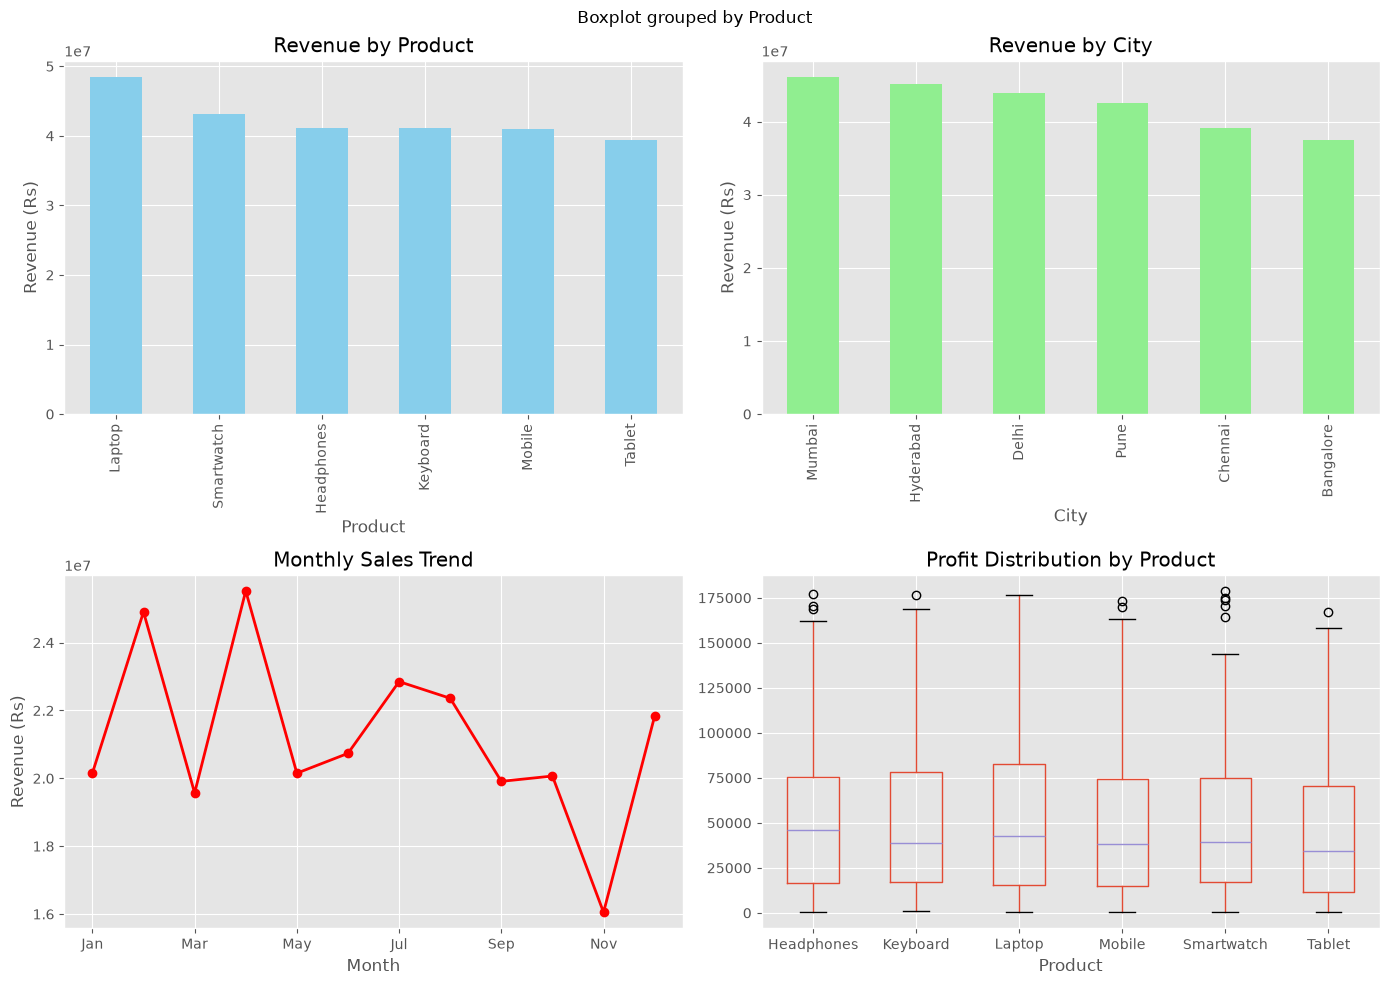

Report saved as sales_analysis_report.csv


In [5]:
# Create 2x2 Dashboard
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Sales Data Analysis Dashboard', fontsize=16, fontweight='bold')

# 1. Product-wise Sales
product_sales.plot(kind='bar', ax=axes[0,0], color='skyblue')
axes[0,0].set_title('Revenue by Product')
axes[0,0].set_ylabel('Revenue (Rs)')

# 2. City-wise Sales
city_sales.plot(kind='bar', ax=axes[0,1], color='lightgreen')
axes[0,1].set_title('Revenue by City')
axes[0,1].set_ylabel('Revenue (Rs)')

# 3. Monthly Trend
monthly_sales.plot(kind='line', marker='o', ax=axes[1,0], color='red', linewidth=2)
axes[1,0].set_title('Monthly Sales Trend')
axes[1,0].set_ylabel('Revenue (Rs)')

# 4. Profit Distribution
df.boxplot(column='Profit', by='Product', ax=axes[1,1])
axes[1,1].set_title('Profit Distribution by Product')

plt.tight_layout()
plt.show()

# Save Report
df.to_csv('sales_analysis_report.csv', index=False)
print("Report saved as sales_analysis_report.csv")

# 📊 Sales Data Analyzer
Exploratory Data Analysis on 1000 rows of retail sales data.

## 🎯 Key Insights
- Total Revenue: ₹2.54 Crore
- Total Profit: ₹50.8 Lakh
- Top City: Mumbai
- Best Month: April
- Top Product: Tablet / Mobile

## 🛠️ Tech Stack
Python, Pandas, Matplotlib, NumPy

## 📊 Dashboard
2x2 Dashboard with Product, City, Monthly Trend & Profit Distribution.